In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
import random
from matplotlib.colors import ListedColormap
import pandas as pd 

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

In [3]:
import os
from PIL import Image

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [5]:
ruta = "dt_lab7/archive/Train"
LADO = 28


rutas = []
for carpeta, _, archivos in os.walk(ruta):
    for archivo in archivos:
        if archivo.lower().endswith((".png", ".jpg", ".jpeg")):
            rutas.append(os.path.join(carpeta, archivo))
print(len(rutas), "imágenes encontradas")


rng = np.random.default_rng(42)
rng.shuffle(rutas)


def cargar(r):
    img = Image.open(r).convert("L").resize((LADO, LADO))
    return np.asarray(img, dtype=np.float32).ravel()

df_emnist = pd.DataFrame([cargar(r) for r in rutas])
print(df_emnist.shape)                # (cantidad de imágenes, LADO*LADO)
df_emnist.head()

27455 imágenes encontradas
(27455, 784)


,0,1,2,3,4,5,6,7,8,9,...,774,775,776,777,778,779,780,781,782,783
0,174.0,174.0,175.0,177.0,181.0,183.0,184.0,184.0,185.0,184.0,...,209.0,204.0,209.0,213.0,212.0,212.0,211.0,211.0,211.0,211.0
1,187.0,187.0,189.0,191.0,193.0,195.0,196.0,197.0,197.0,197.0,...,235.0,237.0,236.0,240.0,241.0,231.0,235.0,234.0,233.0,232.0
2,171.0,173.0,176.0,177.0,178.0,180.0,183.0,185.0,185.0,186.0,...,206.0,200.0,205.0,206.0,198.0,211.0,202.0,201.0,200.0,198.0
3,193.0,193.0,194.0,194.0,194.0,194.0,194.0,195.0,192.0,194.0,...,177.0,177.0,178.0,155.0,115.0,113.0,133.0,137.0,141.0,143.0
4,199.0,198.0,197.0,197.0,197.0,197.0,198.0,199.0,200.0,190.0,...,143.0,133.0,155.0,170.0,186.0,192.0,195.0,186.0,178.0,180.0


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(df_emnist, random_state=42)  
X_test = X_test[:40]
print(X_train.shape, X_test.shape)

(20591, 784) (40, 784)


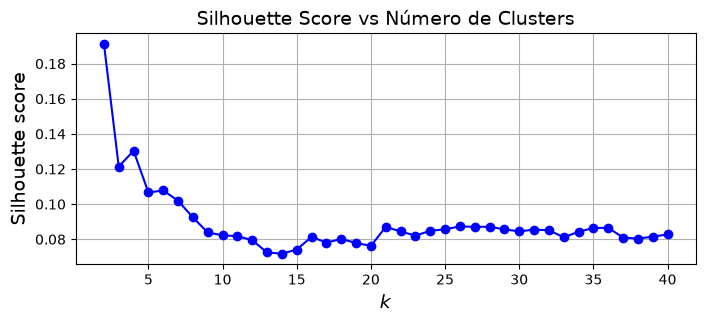

In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=50, random_state=42)
X = pca.fit_transform(X_train) 
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, 10)]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

max_k = 40 # no más de los centros generados
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, max_k + 1)]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]
# Generar eje x para k de 2 hasta max_k
ks = list(range(2, max_k + 1))

# plt.figure(figsize=(8, 3))
# plt.plot(ks, silhouette_scores, "bo-")
# # plt.plot(range(2, 10), silhouette_scores, "bo-")
# plt.xlabel("$k$", fontsize=14)
# plt.ylabel("Silhouette score", fontsize=14)
# plt.axis([1.8, 8.5, 0.55, 0.7])
# plt.show()

plt.figure(figsize=(8, 3))
plt.plot(ks, silhouette_scores, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Silhouette Score vs Número de Clusters", fontsize=14)
plt.grid(True)
plt.show()

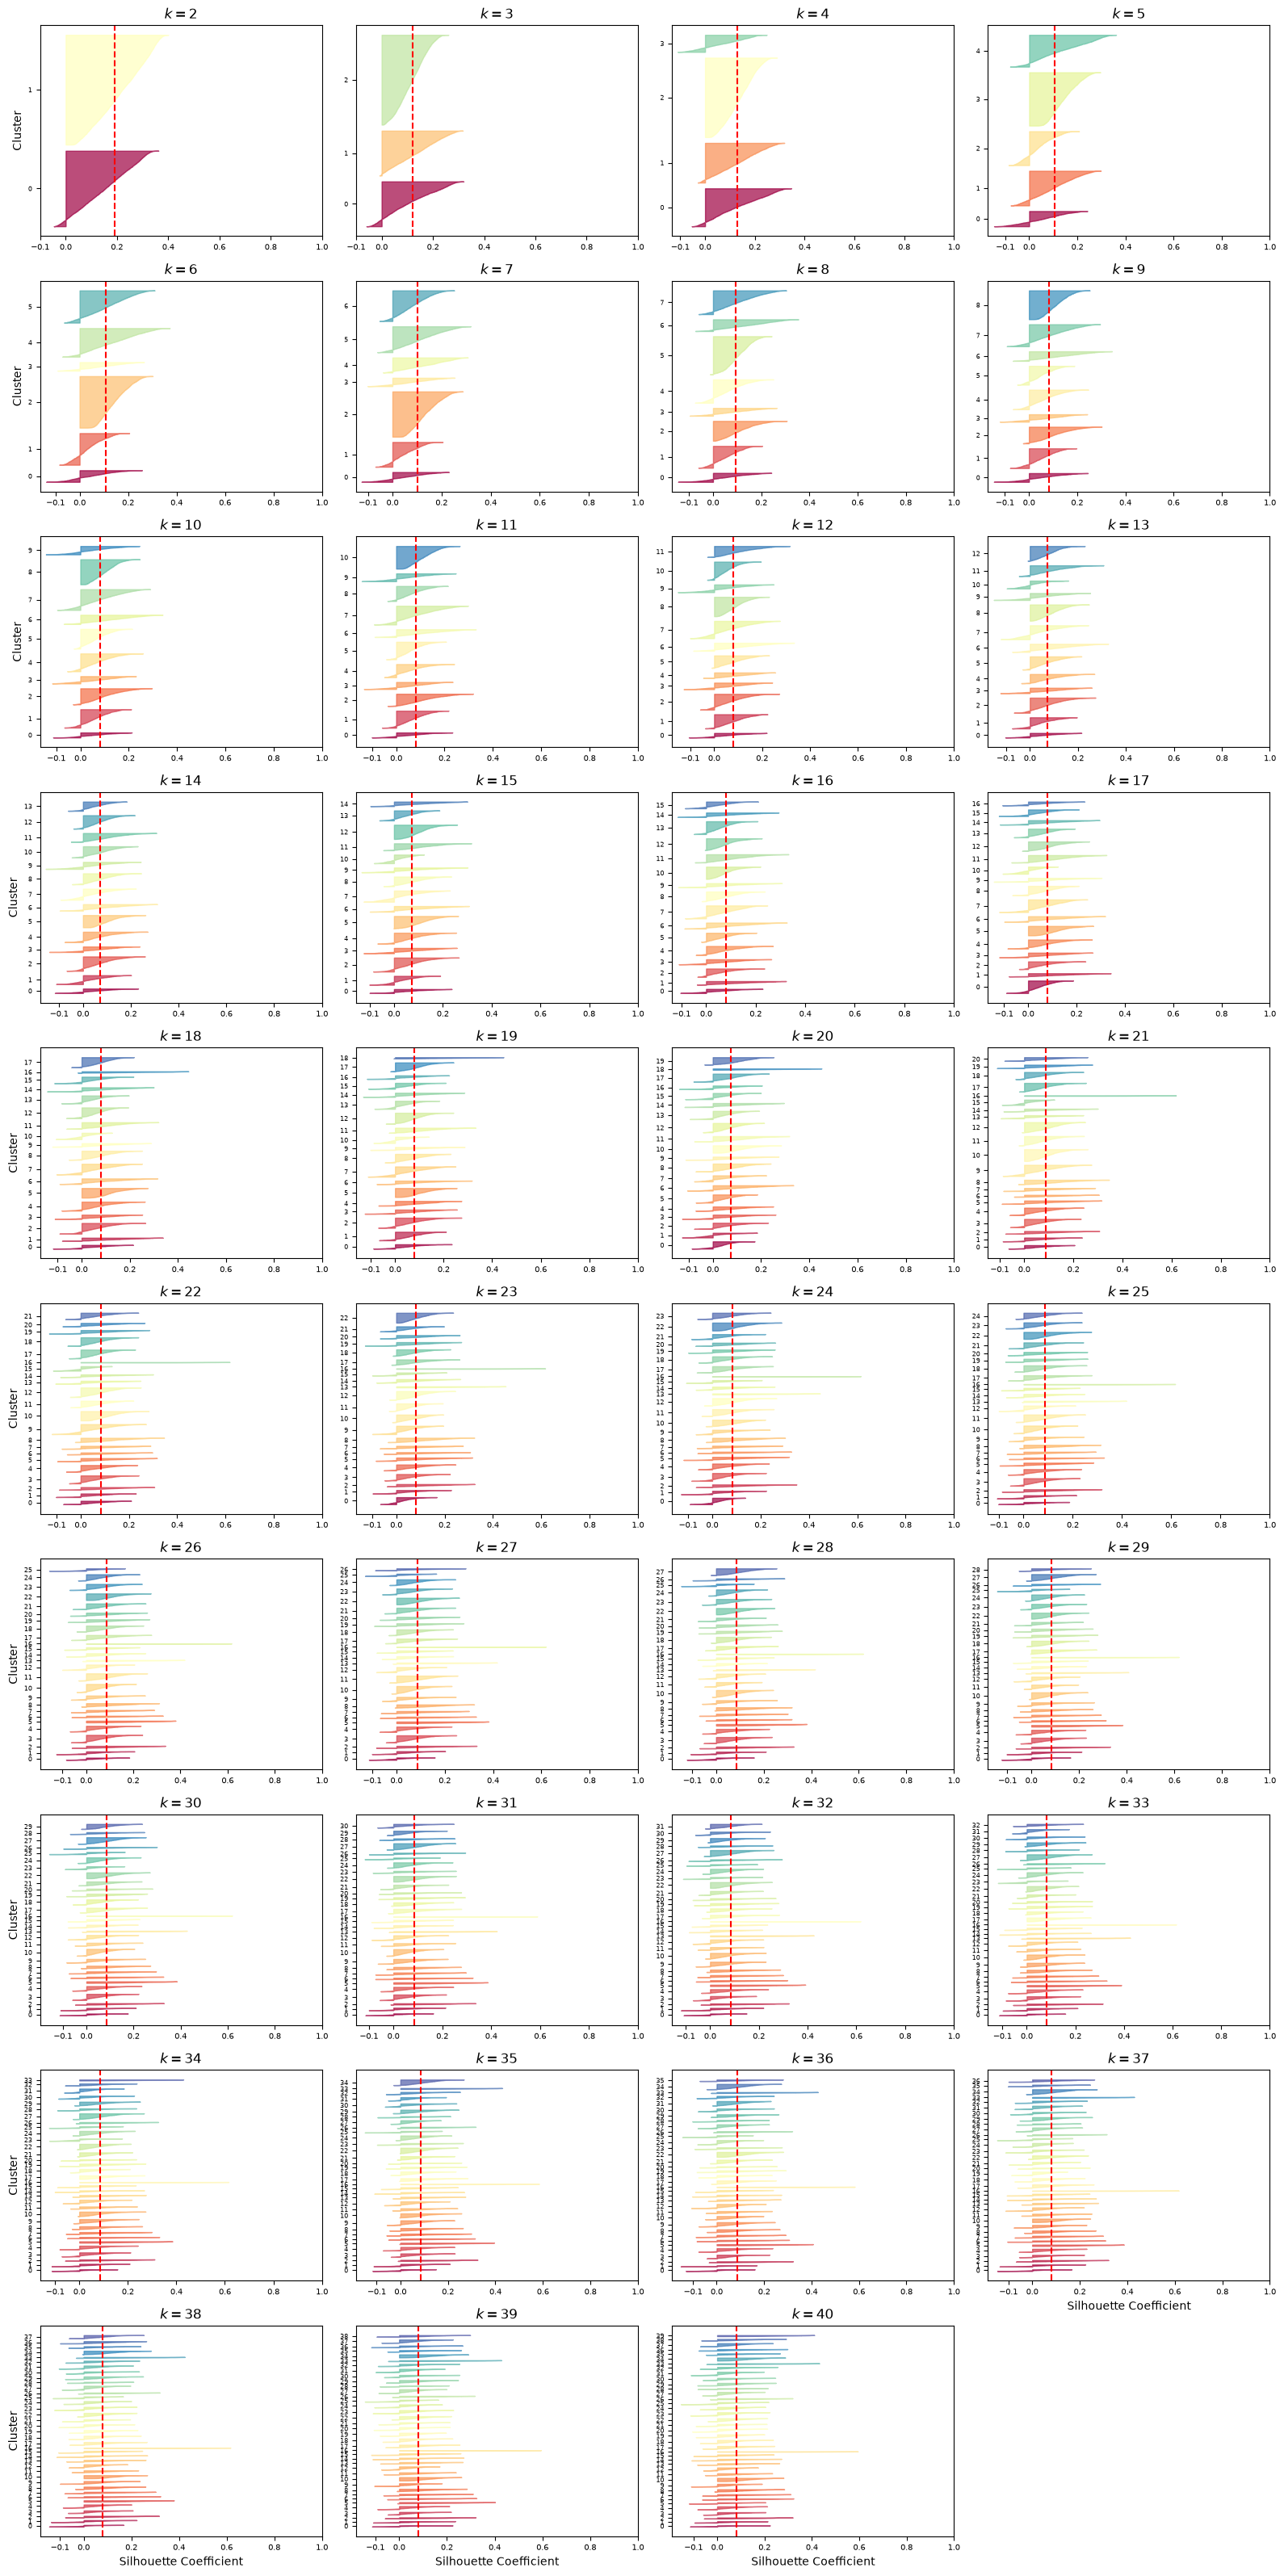

In [10]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter
import matplotlib as mpl

valid_ks = ks                                   # <-- CAMBIO: todos los k (2, 3, ..., max_k)
n_cols = 4                                      # <-- NUEVO: 4 gráficos por fila
n_rows = int(np.ceil(len(valid_ks) / n_cols))   # <-- NUEVO: filas necesarias

plt.figure(figsize=(4 * n_cols, 3.2 * n_rows))  # <-- CAMBIO: el tamaño crece con la cantidad de gráficos

for plot_idx, k in enumerate(valid_ks):
    plt.subplot(n_rows, n_cols, plot_idx + 1)   # <-- CAMBIO: cuadrícula dinámica (antes 2, 2)

    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    plt.tick_params(axis='y', labelsize=6)                          # <-- NUEVO: números de cluster pequeños para que quepan

    if plot_idx % n_cols == 0:                                      # <-- CAMBIO: etiqueta "Cluster" en la primera columna
        plt.ylabel("Cluster")

    plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])         # <-- CAMBIO: se muestra siempre (antes dependía de k in (3,4,5,6))
    plt.tick_params(axis='x', labelsize=7)
    if plot_idx >= len(valid_ks) - n_cols:                          # <-- CAMBIO: etiqueta x solo en la última fila
        plt.xlabel("Silhouette Coefficient")

    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title("$k={}$".format(k), fontsize=12)

plt.tight_layout()                                                  # <-- NUEVO: evita que se solapen los títulos
plt.show()

In [12]:
from sklearn.cluster import KMeans

k = 30
kmeans = KMeans(n_clusters=k, random_state=42)
X_digits_dist = kmeans.fit_transform(X_train)

print(X_digits_dist.shape)

(20591, 30)


In [13]:
print(X_digits_dist.shape)
print(X_digits_dist)

(20591, 30)
[[1379.9082  1943.324   1010.85004 ... 1123.551   1361.5948  1222.9178 ]
 [1659.1519  2163.2036  1684.4972  ... 1585.5812  1487.5753  1861.94   ]
 [1767.676   1939.2415  1842.3394  ... 1840.6536  1661.5015  1663.1898 ]
 ...
 [1005.9407  1453.3691  1194.3839  ... 1451.4569   955.98083 1409.8003 ]
 [1571.0808  2499.0476  1004.33966 ...  951.8966  1762.8087  1486.8301 ]
 [1615.8689  2571.6377  1314.0507  ... 1204.9579  1757.2314  1833.6062 ]]


In [15]:
idxs = np.argmin(X_digits_dist, axis=0)
X_representative_digits = X_train.values[idxs]

In [16]:
print(X_representative_digits.shape)
print(X_representative_digits)

(30, 784)
[[140. 144. 150. ... 108. 119. 178.]
 [198. 198. 199. ... 232. 232. 232.]
 [131. 132. 133. ... 147. 146. 144.]
 ...
 [123. 123. 125. ... 145. 146. 151.]
 [142. 143. 145. ... 193. 193. 193.]
 [134. 135. 137. ... 188. 188. 188.]]


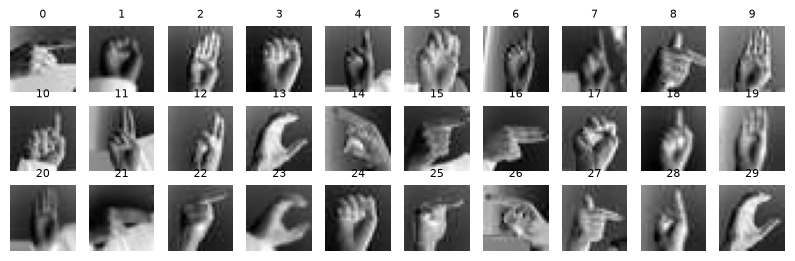

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
for index, X_representative_digit in enumerate(X_representative_digits):
  plt.subplot(5, 10, index+1)
  plt.imshow(X_representative_digit.reshape(28,28), cmap="binary")
  plt.title(index, fontsize=8)
  plt.axis('off')
plt.show()

In [19]:
y_representative_digits = np.array([
    1, 2, 3, 2, 4, 5, 6, 6, 7, 8, 9, 4, 10, 11, 12, 13, 8, 8, 2, 7, 9, 9, 8, 11, 2, 8, 14, 8, 7, 11
])
print(len(y_representative_digits))

30
